# Zachary Weed

In [1]:
!pip install tiktoken

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 994.0/994.0 kB 16.2 MB/s eta 0:00:00

[notice] A new release of pip is available: 24.3.1 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


In [65]:
import tiktoken
import torch
import torch.nn as nn
from torch.nn import functional as F

from torch.utils.data import Dataset, DataLoader

# [Problem 1] - Working With Tiktoken Library

**Problem 1.** Try the BPE tokenizer from the `tiktoken` library on the unknown words `"Malavrba mrda"` and print the individual token IDs. Then, call the function on each of the resulting decode integers in this list to create the mapping similar to slide 27. Lastly, call the `decode` method on the token IDs to check whether it can reconstruct the original input `"Malavrba mrda"`.

### Encodes an unknown string with the GPT2 - Generative Pre-trained Transformer 2

In [3]:
tokenizer = tiktoken.get_encoding('gpt2')

text = "Malavrba mrda"
integers = tokenizer.encode(text)
print(integers)

[15029, 615, 81, 7012, 285, 4372, 64]


### Decodes each of the integers for a sequence of tokens, in many cases it is not 1:1 word:token, as it is Byte-Pair Encoding 

In [4]:
for i in integers:
    print(f"{i} -> {tokenizer.decode([i])}")

15029 -> Mal
615 -> av
81 -> r
7012 -> ba
285 ->  m
4372 -> rd
64 -> a


### Reconstructing the original string from the sequences of encoded tokens

In [5]:
strings = tokenizer.decode(integers)
print(strings)
assert strings == text

Malavrba mrda


# [Problem 2] - Tokenizing Shakespeare

**Problem 2.** Starting with the attached Jupyter notebook `ch02.ipynb` and the complete Shakespeare works contained in teh file `t8.shakespeare.txt`. Remove teh beginning portion of the text related to the project Gutenberg and copyright notices. Tokenize the text using TikTokenizer with GPT-4 model. How big is your vocabulary. Pickup two consecutive sentences somewhere in the text. Separate two sentences with `<|endoftext|>` symbol. Demonstrate that you can transform that text into a sequence of numerical IDs and then revert sequence of number into a text.

### Tokenizing Material and Identifying Length of Corpus

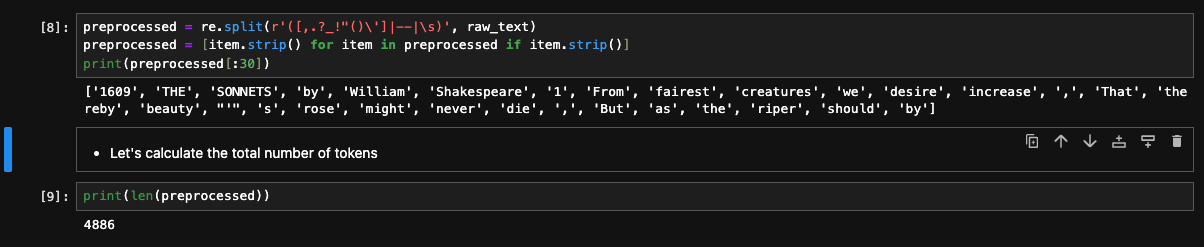

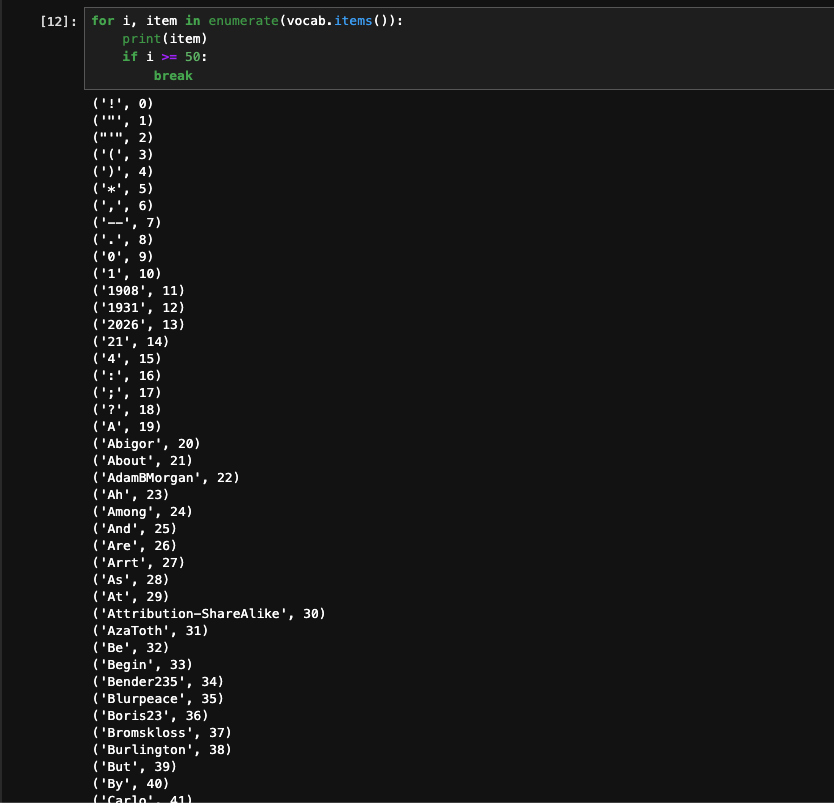

A majority of the work here involved writing `the-verdict.txt` file into the directory and calling this code. What we find is the tokenized representation of each token of the text, with a respective ID for the string

### Selecting two sentence for tokenization

```python
    sentences = "Is this the fashions in the court of England?<|endoftext|>Believe then, if you please, that I can do strange things."
```

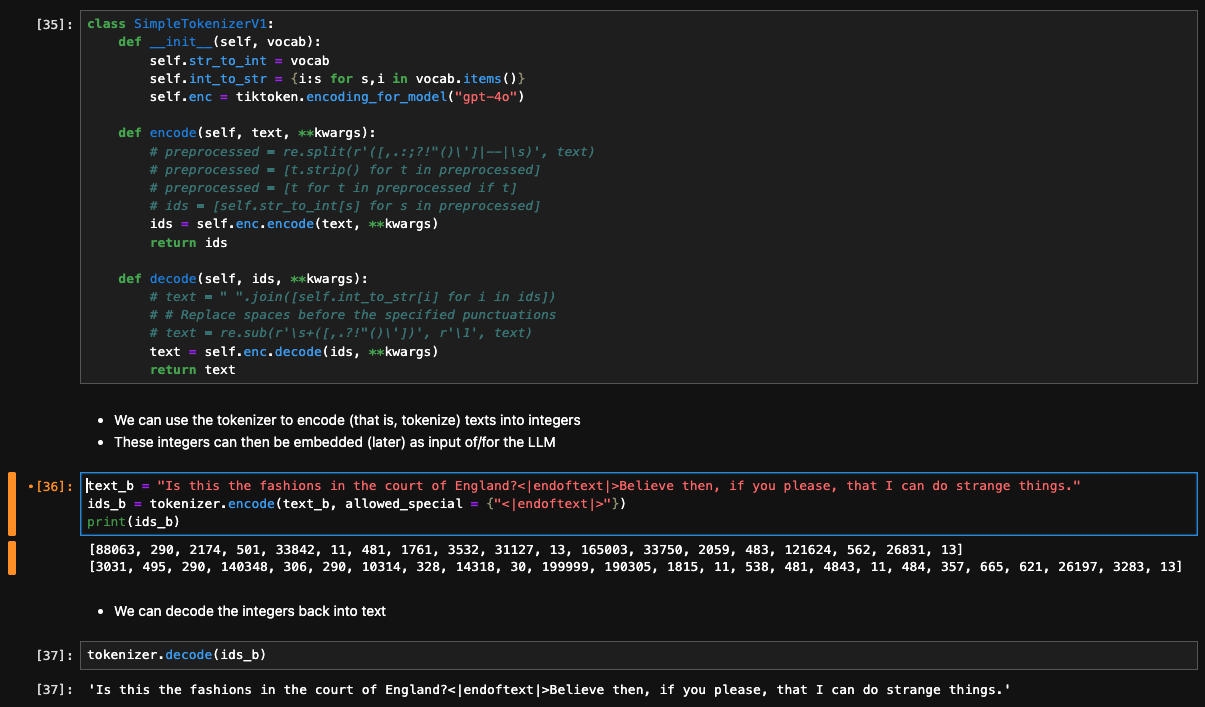

Resulting from minor modifications made to the code, we were able to decode encoded strings.

# [Problem 3] -

**Problem 3.** Construct a `DataLoader` that could feed your transformer network with batches of 4 samples of length 6 tokens at a time. Demonstrate that you can load data in sliding windows. When demonstrating sliding windows, first print tokens as numbers. Then, try printing tokens as "words".

### Some initial Setup with Batches, Block Size, Head Count, etc.

In [ ]:
device = 'cpu'
# n parallel sequences
batch_size = 32
eval_iterations = 10
number_of_embeddings = 384
block_size = 8
number_of_embeddings = 32
n_head = 8
number_of_layers = 4
learning_rate = 1e-2
max_iterations = 2999
eval_interval = 299

torch.manual_seed(1337)

In [101]:
class GPTDatasetV1(Dataset):
    """
    This code is an adaptation of the
    Original GPTDatasetV1 from the slides.
    This work incorporates a sliding window
    Which allows for a varaible length
    And width attention span, essentially

    max_length: represents window length
    stride: represents step size
    """
    def __init__(self, text, tokenizer, max_length, stride):
        self.max_length = max_length
        self.stride = stride
        self.tokenizer = tokenizer
        
        token_ids = tokenizer.encode(text)
        self.tokens = torch.tensor(token_ids, dtype = torch.long)

        # from where each attention span starts
        self.n = (len(self.tokens) - max_length -1) // stride + 1

    def __len__(self):
        return self.n

    def __getitem__(self, index):
        i = index * self.stride
        x = self.tokens[i : i + self.max_length]
        y = self.tokens[i + 1 : i + self.max_length + 1]
        return x, y

def create_dataloader(text, batch_size = 4, max_length = 256, stride = 128, shuffle = True):
    tokenizer = tiktoken.get_encoding("gpt2")
    dataset = GPTDatasetV1(text, tokenizer, max_length, stride)
    dataloader = DataLoader(dataset, batch_size = batch_size, shuffle = shuffle)
    return dataloader, tokenizer

In [102]:
class FeedForward(nn.Module):
    def __init__(self, number_of_embeddings):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(number_of_embeddings, 4 * number_of_embeddings),
            nn.ReLU(),
            nn.Linear(4 * number_of_embeddings, number_of_embeddings)
        )

    def forward(self, x):
        return self.net(x)

In [103]:
class Block(nn.Module):
    def __init__(self, number_of_embeddings, number_of_heads):
        super().__init__()
        head_size = number_of_embeddings // number_of_heads
        self.sa = MultiHeadAttention(number_of_heads, head_size)
        self.feed_forward = FeedForward(number_of_embeddings)
        self.ln1 = nn.LayerNorm(number_of_embeddings)
        self.ln2 = nn.LayerNorm(number_of_embeddings)

    def forward(self, x):
        x = x + self.sa(x)
        return x + self.feed_forward(x)

In [115]:
# The head for applying the attention model
# Considered distinctly different from
# Next token predictions
class Head(nn.Module):
    def __init__(self, head_size, number_of_embeddings, block_size):
        super().__init__()
        """
        For every token, three vectors are built:

        Key(k): The actual token
        Query(q): What content a token wants
        Value(v): What information a token has
        """
        self.key = nn.Linear(number_of_embeddings, head_size, bias = False)
        self.query = nn.Linear(number_of_embeddings, head_size, bias = False)
        self.value = nn.Linear(number_of_embeddings, head_size, bias = False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))

    def forward(self, x):
        BATCH, TIME, CHANNELS = x.shape
        """
        - emits 2 vectors: a Query (what is wanted) and a Key (the token)
        - performs dot product on keys & queries
        """
        key = self.key(x) # (BATCH, TIME, CHANNEL)
        query = self.query(x) # (BATCH, TIME, CHANNEL)
        # for sqrt(dk) as defined by Vaswani, et al. 2017
        dk = key.shape[-1]

        # computes attention scores
        # (BATCH, TIME, CHANNEL) @ (BATCH, CHANNEL, TIME): (BATCH, TIME, TIME)
        attention_scores = query @ key.transpose(-2, -1) * dk ** -0.5
        # (BATCH, TIME, TIME)
        attention_scores = attention_scores.masked_fill(self.tril[:TIME, :TIME] == 0, float('-inf'))
        # (BATCH, TIME, TIME)
        attention_scores = F.softmax(attention_scores, dim = -1)
        # perform weighted aggregation of values
        # (BATCH, TIME, CHANNELS)
        value = self.value(x)
        # (BATCH, TIME, TIME) @ (BATCH, TIME, CHANNELS): (BATCH, TIME, CHANNELS)
        return attention_scores @ value

In [116]:
class MultiHeadAttention(nn.Module):
    def __init__(self, number_of_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size, number_of_embeddings, block_size) for _ in range(number_of_heads)])

    def forward(self, x):
        return torch.cat([h(x) for h in self.heads], dim = -1)

In [117]:
class Transformer(nn.Module):
    def __init__(self, vocabulary_size, number_of_embeddings, block_size):
        super().__init__()
        self.sa_heads = MultiHeadAttention(4, block_size)
        self.token_embedding_table = nn.Embedding(vocabulary_size, number_of_embeddings)
        self.position_embedding_table = nn.Embedding(block_size, number_of_embeddings)
        self.feed_forward = FeedForward(number_of_embeddings)
        self.blocks = nn.Sequential(
            *[Block(number_of_embeddings, number_of_heads = n_head) for _ in range(number_of_layers)]
        )
        self.lm_head = nn.Linear(number_of_embeddings, vocabulary_size)

    def forward(self, index, targets = None):
        BATCH, TIME = index.shape
        # BATCH, TIME, CHANNELS
        token_embeddings = self.token_embedding_table(index)
        # TODO: implement CUDA if needed
        positional_embeddings = self.position_embedding_table(torch.arange(TIME, device = 'cpu'))
        # (BATCH, TIME, CHANNEL)
        x = token_embeddings + positional_embeddings
        x = self.blocks(x)
        # (BATCH, TIME, vocabulary_size)
        logits = self.lm_head(x)

        if targets is None:
            loss = None
        else:
            BATCH, TIME, CHANNELS = logits.shape
            logits = logits.view( BATCH * TIME, CHANNELS)
            targets = targets.view(BATCH * TIME)
            # identifies quality of logits (related with targets)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, index, max_new_tokens, block_size = 8):
        # index: (BATCH, TIME) array of indices in context
        for _ in range(max_new_tokens):
            # basically the scope of what
            # can be focused upon at a given interval
            # where block_size essentially represents
            # a given window of attention
            index_conditioned = index[:, -block_size:]
            logits, loss = self(index_conditioned)
            # (BATCH, CHANNELS)
            logits = logits[:, -1, :]
            # application of softmax()
            probabilities = F.softmax(logits, dim = -1)
            # samples from probability distribution
            # (BATCH, 1)
            index_of_next = torch.multinomial(probabilities, num_samples = 1)
            # appends aforementioned characters on sequence
            index = torch.cat((index, index_of_next), dim = 1)
        return index

### Demonstrating the concept of a SlidingWindow Dataset in a Transformer

In [118]:
# Here we load in some Shakespeare work
with open('the-verdict.txt', 'r', encoding = 'utf-8') as f:
    text = f.read()
####
####
####
# Requirment of 4 samples per batch, 6 tokens lengths per batch
# This code represents the requirements of:
#   a) 4 samples per batch
#   b) 6 token length per batch
dataloader, tokenizer = create_dataloader(
    text, 
    batch_size = 4, 
    max_length = 6, 
    stride = 1, 
    shuffle = False
)
print("Number of windows:", len(dataloader.dataset))
xb, yb = next(iter(dataloader))
# Expectation: (4,6)
print("xb shape:", xb.shape)
# Expectation: (4, 6)
print("yb shape:", yb.shape)
####
####
####


###
###
###
# Demonstrates Sliding Window as TokenIDs and then decoded
# Where the sliding window indicates what things look
# Like as the window is shifted larger and smaller
print("Token IDs (xb)")
print("xb") # raw token ids
print("Shape:", xb.shape)


print("Decoded Windows")
for i in range(xb.shape[0]):
    token_ids = xb[i].tolist()
    decoded_text = tokenizer.decode(token_ids)
    print(f"Sample {i}:")
    print("token_ids:", token_ids)
    print("decoded:", repr(decoded_text))
    print("\n")
###
###
###

Number of windows: 1847428
xb shape: torch.Size([4, 6])
yb shape: torch.Size([4, 6])
Token IDs (xb)
xb
Shape: torch.Size([4, 6])
Decoded Windows
Sample 0:
token_ids: [1433, 2931, 198, 198, 10970, 311]
decoded: '1609\n\nTHE S'


Sample 1:
token_ids: [2931, 198, 198, 10970, 311, 1340]
decoded: '09\n\nTHE SON'


Sample 2:
token_ids: [198, 198, 10970, 311, 1340, 12884]
decoded: '\n\nTHE SONNET'


Sample 3:
token_ids: [198, 10970, 311, 1340, 12884, 50]
decoded: '\nTHE SONNETS'




# [Problem 4] -

**Problem 4.** Please, consider script `transformer_walkthrough`.py. Different case numbers from 1 to 7 gradually build the Transformer architecture. Please run this code for case = 1 and case = 6 and compare the outputs. Convince yourself that the output is more "English like" with the higher case value. You are welcome to experiment with other case numbers. Please submit outputs of your runs. Please submit working code, especially if you modify the code.

### Case 1

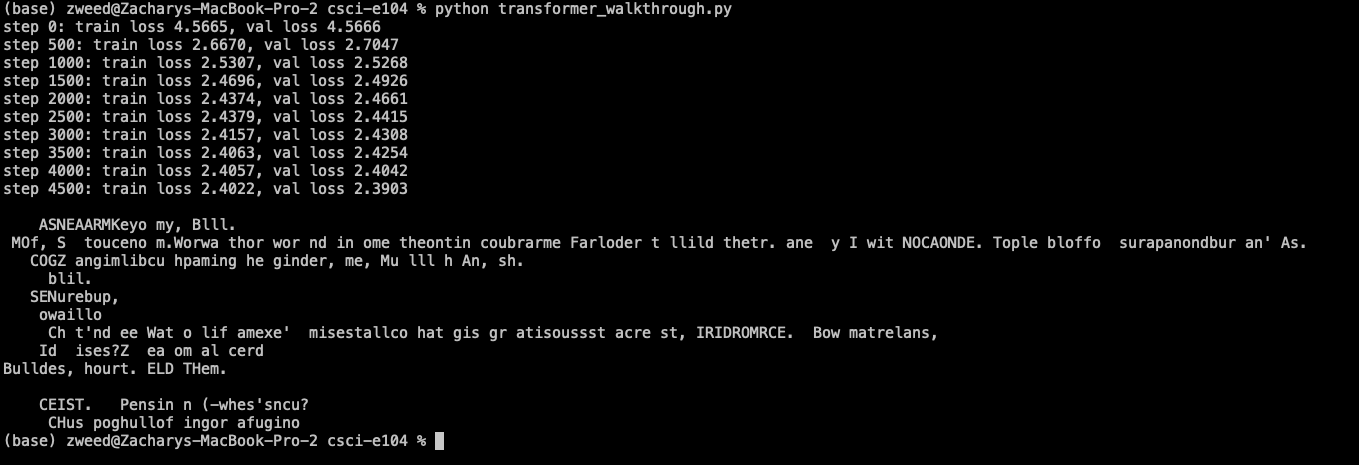

### Case 6

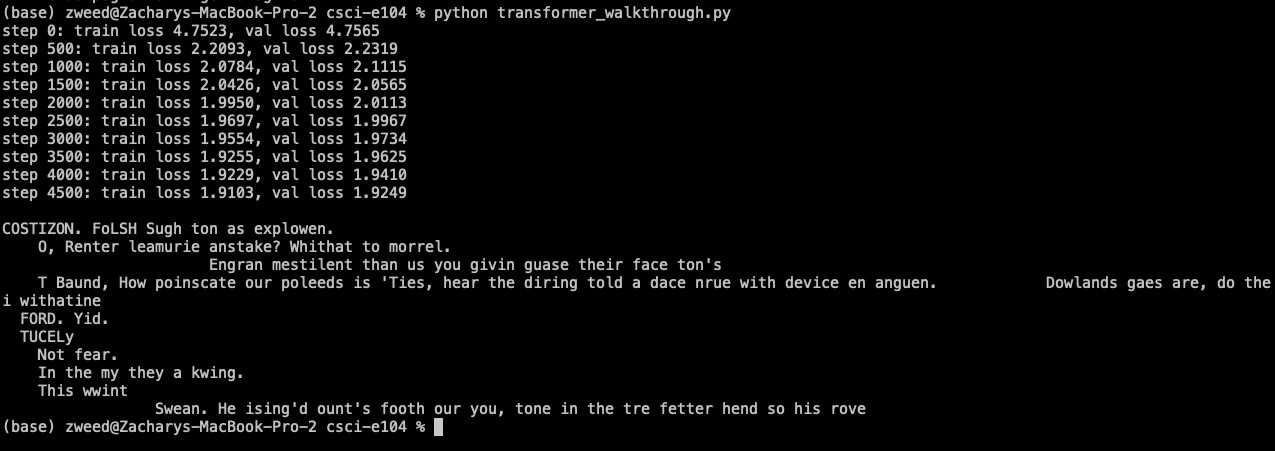

### Comparison

#### Case 1 - Words & Subwords:
Arm (subword), yo (subword), My, Key (subword), of (subword), to (subword), no (subword), thor, or (subword), in, the (subword), on (subword), bra (subword), arm (subword), me (subword), far (subword), lil (subword), the (subword), I, wit, no (subword), on (subword), Top (subword), to (subword), of (subword), off (subword), sur (subword), pan (subword), on (subword), non (subword), an, cog (subword), an (subword), am (subword), he, gin (subword), me, an (subword), sh, up (subword), ow (subword), ill (subword), if (subword), is (subword), at (subword), is (subword), sous (subword), hat, acre, st (abbreviation), bow, mat (subword), om, Bull (subword), THem, he (subword), us (subword), hull (subword), of (subword), in (subword), no (subword), us (subword)

**Total: 61**

#### Case 2 - Words & Subwords:
SH, take (subword), whit (subword), hat (subword), to, lent (subword), than, us, you, givin, their, face, ton, how, cat(subword), our, leeds (subword), ties, head, the, ring (subword), told, a, with, device, land (subword), are, do, the, with, hat (subword), ford, not, fear, in, the, my, they, a, wing, this, he, foot (subword), our, you, tone, ton (subword), one (subword), end (subword), so, his

**Total: 51**

#### Summary

- In terms of execution, Case 6 took longer for completion
- Overall training loss was less in Case 6
- Overall validation loss was less in Case 6
- Things ended up far more like english in Case 6 than Case 1, specifically in terms of full, non-subwords
- In case 1 there were 19% more words, while including subwords
- Thus, it would be of different focus Case 1, requiring a different focus than Case 6